# DSCI 552: HW5
- **Name:** Pavanitha Manche
- **USC ID:** 2866839249
- **GitHub Username:** Pavanitha09

In [86]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')

## 1. Decision Trees as Interpretable Models

### 1(a) Data Loading

In [87]:
data_path = '../data/'
FEATURES = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains', 'burning_urethra']
LABELS = ['bladder_inflammation', 'nephritis']

acute = pd.read_csv(data_path + 'diagnosis.data', sep='\t', header=None, decimal=',',
                    encoding='utf-16', names=FEATURES + LABELS)
for col in FEATURES[1:] + LABELS:
    acute[col] = (acute[col].str.strip() == 'yes').astype(int)

display(acute.head())

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### 1(b) Decision Tree on the Whole Data Set

**Label powerset** is used (more relevant here): the 2 labels give only 4 classes, and one tree can use the dependence between the two diseases, which binary relevance ignores.

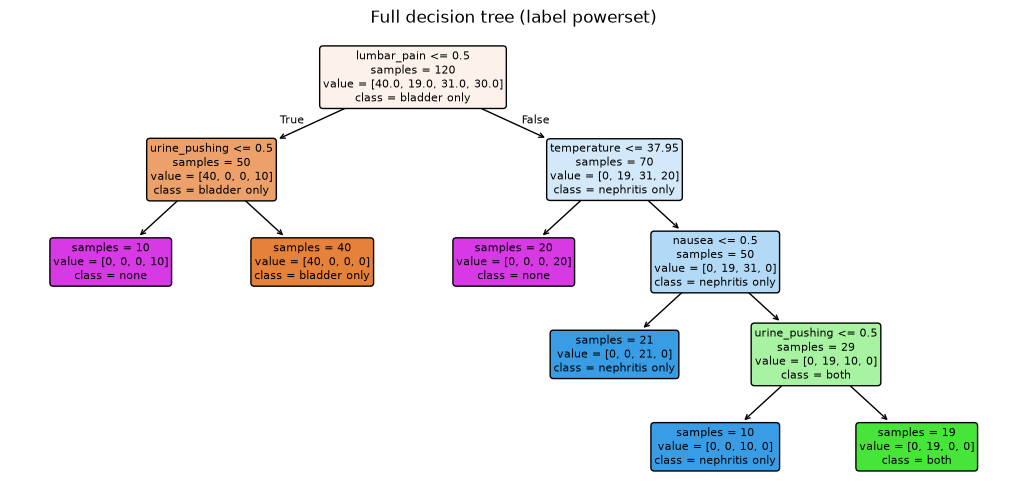

In [88]:
POWERSET = {(0, 0): 'none', (1, 0): 'bladder only', (0, 1): 'nephritis only', (1, 1): 'both'}
X1 = acute[FEATURES]
y1 = acute[LABELS].apply(lambda r: POWERSET[tuple(r)], axis=1)
tree = DecisionTreeClassifier(random_state=42).fit(X1, y1)

def draw_tree(model, title, size=(13, 6)):
    plt.figure(figsize=size)
    plot_tree(model, feature_names=FEATURES, class_names=list(model.classes_), filled=True,
              rounded=True, impurity=False, fontsize=8)
    plt.title(title)
    plt.show()

draw_tree(tree, 'Full decision tree (label powerset)')

### 1(c) IF-THEN Rules

In [89]:
def tree_rules(model):
    t, rules = model.tree_, []
    def recurse(node, conds):
        if t.feature[node] < 0:   # leaf
            cls = model.classes_[np.argmax(t.value[node])]
            rules.append(f"IF {' AND '.join(conds) or 'TRUE'} THEN {cls}  ({int(t.n_node_samples[node])} samples)")
            return
        name, thr = FEATURES[t.feature[node]], t.threshold[node]
        if name == 'temperature':
            left, right = f'temperature <= {thr:.2f}', f'temperature > {thr:.2f}'
        else:
            left, right = f'{name} = no', f'{name} = yes'
        recurse(t.children_left[node], conds + [left])
        recurse(t.children_right[node], conds + [right])
    recurse(0, [])
    return rules

for i, rule in enumerate(tree_rules(tree), start=1):
    print(f'Rule {i}: {rule}')

Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN none  (10 samples)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN bladder only  (40 samples)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN none  (20 samples)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = no THEN nephritis only  (21 samples)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = no THEN nephritis only  (10 samples)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = yes THEN both  (19 samples)


### 1(d) Cost-Complexity Pruning

In [90]:
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(X1, y1)
cv1 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for alpha in path.ccp_alphas:
    m = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    acc = cross_val_score(m, X1, y1, cv=cv1, scoring='accuracy').mean()
    m.fit(X1, y1)
    rows.append({'ccp_alpha': alpha, 'leaves': m.get_n_leaves(), 'depth': m.get_depth(),
                 'CV accuracy': acc, 'train accuracy': m.score(X1, y1)})
prune_df = pd.DataFrame(rows)
display(prune_df.round(4).T)

best_acc = prune_df['CV accuracy'].round(6).max()
best_alpha = prune_df.loc[prune_df['CV accuracy'].round(6) == best_acc, 'ccp_alpha'].max()
pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha).fit(X1, y1)
print(f'Chosen ccp_alpha = {best_alpha:.4f}: leaves = {pruned.get_n_leaves()}, depth = {pruned.get_depth()}, '
      f'CV accuracy = {best_acc:.4f}, training accuracy = {pruned.score(X1, y1):.4f}')

,0,1,2,3,4
ccp_alpha,0.0000,0.0982,0.1333,0.1820,0.2229
leaves,6.0000,4.0000,3.0000,2.0000,1.0000
depth,4.0000,2.0000,2.0000,1.0000,0.0000
CV accuracy,0.9917,0.8583,0.7583,0.6667,0.4833
train accuracy,1.0000,0.8417,0.7583,0.5917,0.3333


Chosen ccp_alpha = 0.0000: leaves = 6, depth = 4, CV accuracy = 0.9917, training accuracy = 1.0000


In [91]:
for i, rule in enumerate(tree_rules(pruned), start=1):
    print(f'Rule {i}: {rule}')
next_alpha = prune_df.loc[prune_df['ccp_alpha'] > best_alpha, 'ccp_alpha'].min()
smaller = DecisionTreeClassifier(random_state=42, ccp_alpha=next_alpha).fit(X1, y1)
print(f'\nMost compact readable tree (ccp_alpha = {next_alpha:.4f}, {smaller.get_n_leaves()} leaves):')
for i, rule in enumerate(tree_rules(smaller), start=1):
    print(f'Rule {i}: {rule}')

Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN none  (10 samples)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN bladder only  (40 samples)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN none  (20 samples)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = no THEN nephritis only  (21 samples)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = no THEN nephritis only  (10 samples)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = yes THEN both  (19 samples)

Most compact readable tree (ccp_alpha = 0.0982, 4 leaves):
Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN none  (10 samples)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN bladder only  (40 samples)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN none  (20 samples)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 THEN nephritis only  (50 samples)


* The largest α with the best CV accuracy is α = 0, so the 6-rule tree is the minimal tree with no loss in accuracy.
* The most compact option is the 4-rule tree (α = 0.0982): easier to read, but CV accuracy drops to 85.83% because it cannot separate "both" from "nephritis only".

## 2. The LASSO and Boosting for Regression

### 2(a) Data Loading and Train / Test Split

In [92]:
with open(data_path + 'communities.names') as f:
    COLS = [line.split()[1] for line in f if line.startswith('@attribute')]

crime = pd.read_csv(data_path + 'communities.data', header=None, names=COLS, na_values='?')
TARGET = 'ViolentCrimesPerPop'

train_raw, test_raw = crime.iloc[:1495], crime.iloc[1495:]

### 2(b) Missing Values and Non-Predictive Features

* Dropping the 5 non-predictive features; missing values are imputed with the training-set **median**.

In [93]:
NON_PREDICTIVE = ['state', 'county', 'community', 'communityname', 'fold']
FEATS = [c for c in COLS if c not in NON_PREDICTIVE + [TARGET]]

imputer = SimpleImputer(strategy='median').fit(train_raw[FEATS])
X_train = pd.DataFrame(imputer.transform(train_raw[FEATS]), columns=FEATS, index=train_raw.index)
X_test = pd.DataFrame(imputer.transform(test_raw[FEATS]), columns=FEATS, index=test_raw.index)
y_train, y_test = train_raw[TARGET], test_raw[TARGET]
X_all = pd.concat([X_train, X_test])

### 2(c) Correlation Matrix

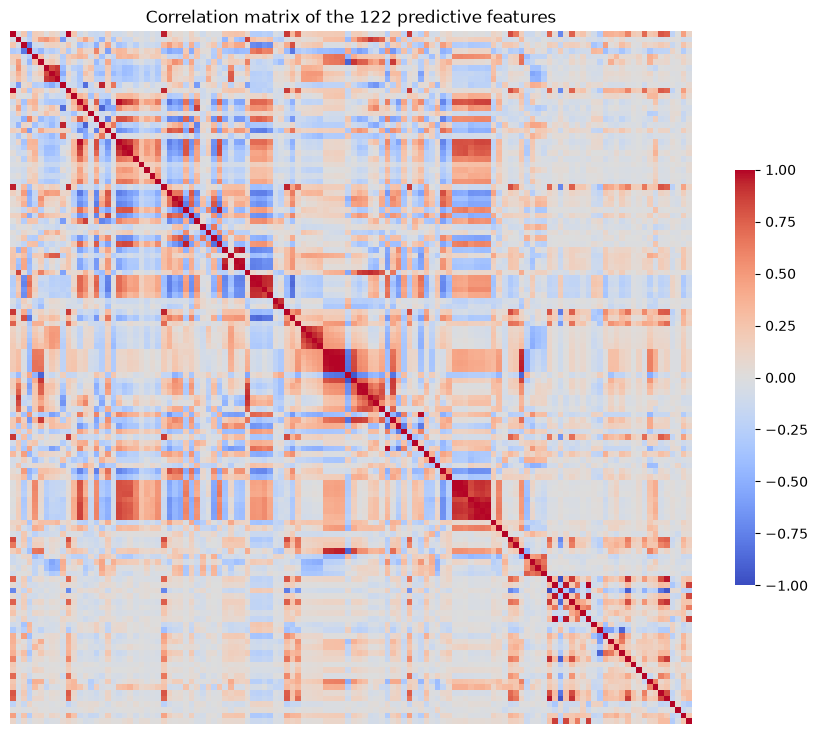

In [94]:
corr = X_all.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, xticklabels=False, yticklabels=False,
            cbar_kws={'shrink': 0.6})
plt.title('Correlation matrix of the 122 predictive features')
plt.show()

### 2(d) Coefficient of Variation

,Feature,CV,Feature,CV,Feature,CV,Feature,CV
0,PctPolicAsian,5.448,OwnOccMedVal,0.879,PctOccupManu,0.508,PctEmploy,0.347
1,NumStreet,4.408,OwnOccHiQuart,0.875,whitePerCap,0.508,MedRentPctHousInc,0.346
2,NumInShelters,3.485,PopDens,0.872,PctImmigRec8,0.505,PctSameHouse85,0.339
3,NumIlleg,2.994,PctWOFullPlumb,0.849,agePct16t24,0.495,PctHousOwnOcc,0.338
4,NumImmig,2.900,OwnOccLowQuart,0.848,MedOwnCostPctIncNoMtg,0.477,PctWorkMomYoungKids,0.336
5,LemasPctOfficDrugUn,2.555,MedNumBR,0.811,HispPerCap,0.474,PctBornSameState,0.336
6,NumUnderPov,2.305,indianPerCap,0.810,MedYrHousBuilt,0.470,LemasGangUnitDeploy,0.333
7,population,2.204,PctLargHouseOccup,0.757,PersPerRentOccHous,0.468,PctWorkMom,0.333
8,LemasSwornFT,2.081,PctPopUnderPov,0.754,PctImmigRec10,0.456,PctKids2Par,0.332
9,numbUrban,2.002,PctPolicBlack,0.745,PctPolicMinor,0.443,PctFam2Par,0.331


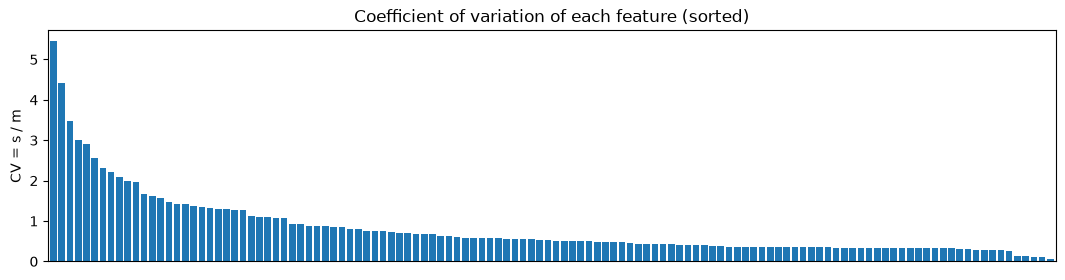

In [95]:
cv_feat = (X_all.std(ddof=1) / X_all.mean()).sort_values(ascending=False)
blocks = [cv_feat.iloc[i:i + 31].round(3).reset_index().set_axis(['Feature', 'CV'], axis=1)
          for i in range(0, len(cv_feat), 31)]
display(pd.concat(blocks, axis=1).fillna(''))

cv_feat.plot.bar(figsize=(13, 3), width=0.8, xticks=[])
plt.title('Coefficient of variation of each feature (sorted)')
plt.ylabel('CV = s / m')
plt.show()

### 2(e) Scatter plots and box plots for highest CV features

,PctPolicAsian,NumStreet,NumInShelters,NumIlleg,NumImmig,LemasPctOfficDrugUn,NumUnderPov,population,LemasSwornFT,numbUrban,HousVacant
CV,5.4478,4.4077,3.4855,2.9942,2.9005,2.5553,2.305,2.2035,2.0807,2.0017,1.9588


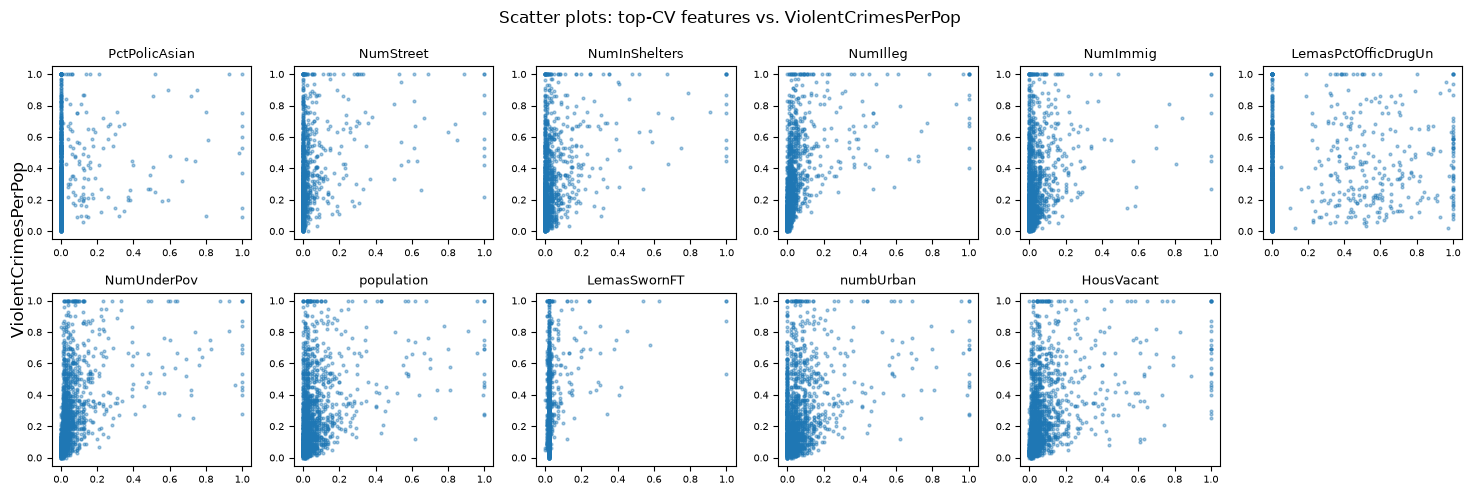

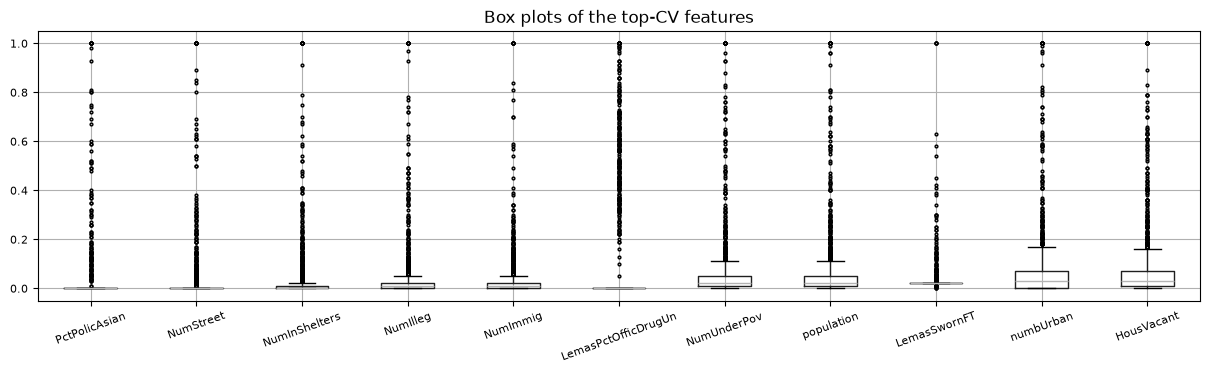

In [96]:
top = list(cv_feat.index[:int(np.floor(np.sqrt(128)))])
display(cv_feat[top].round(4).to_frame('CV').T)

fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for ax, col in zip(axes.flat, top):
    ax.scatter(X_all[col], crime[TARGET], s=4, alpha=0.4)
    ax.set_title(col, fontsize=9)
    ax.tick_params(labelsize=7)
axes.flat[-1].axis('off')
fig.supylabel(TARGET)
fig.suptitle('Scatter plots: top-CV features vs. ViolentCrimesPerPop')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(15, 3.5))
X_all[top].boxplot(ax=ax, fontsize=8, flierprops={'markersize': 2})
ax.set_title('Box plots of the top-CV features')
plt.xticks(rotation=20)
plt.show()

* **No.** The scatter plots only show weak, noisy one-feature relationships; significance depends on the other correlated features and needs a fitted model and a test (p-value).

### 2(f) Linear Model (Least Squares)

In [97]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def report(name, model):
    print(f'{name}: test MSE = {mean_squared_error(y_test, model.predict(X_test)):.5f}')

ols = LinearRegression().fit(X_train, y_train)
report('Least squares', ols)

Least squares: test MSE = 0.01797


### 2(g) Ridge Regression (λ by 5-Fold CV)

In [98]:
LAMBDAS = np.logspace(-4, 3, 50)
ridge_cv = GridSearchCV(Ridge(), {'alpha': LAMBDAS}, cv=kf, scoring='neg_mean_squared_error').fit(X_train, y_train)
print(f'Best lambda = {ridge_cv.best_params_["alpha"]:.4g}, CV MSE = {-ridge_cv.best_score_:.5f}')
report('Ridge', ridge_cv.best_estimator_)

Best lambda = 3.728, CV MSE = 0.01942
Ridge: test MSE = 0.01746


### 2(h) LASSO (λ by 5-Fold CV), Raw and Standardized Features

In [99]:
LASSO_LAMBDAS = np.logspace(-5, -1, 40)

def fit_lasso(steps, name):
    pipe = Pipeline(steps + [('lasso', Lasso(max_iter=50000))])
    gs = GridSearchCV(pipe, {'lasso__alpha': LASSO_LAMBDAS}, cv=kf, scoring='neg_mean_squared_error').fit(X_train, y_train)
    coef = pd.Series(gs.best_estimator_['lasso'].coef_, index=FEATS)
    chosen = coef[coef != 0]
    print(f'{name}: best lambda = {gs.best_params_["lasso__alpha"]:.4g}, CV MSE = {-gs.best_score_:.5f}, '
          f'{len(chosen)} of {len(FEATS)} variables selected')
    report(name, gs.best_estimator_)
    print('Selected variables:', ', '.join(chosen.index), '\n')

fit_lasso([], 'LASSO (raw features)')
fit_lasso([('scale', StandardScaler())], 'LASSO (standardized features)')

LASSO (raw features): best lambda = 0.0001061, CV MSE = 0.01952, 74 of 122 variables selected
LASSO (raw features): test MSE = 0.01765
Selected variables: racepctblack, racePctAsian, agePct12t21, agePct12t29, agePct65up, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctBSorMore, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctSameC

* Test MSE is essentially equal (raw 0.01765 vs. standardized 0.01770), since the features are already normalized.

### 2(i) Principal Component Regression (M by 5-Fold CV)

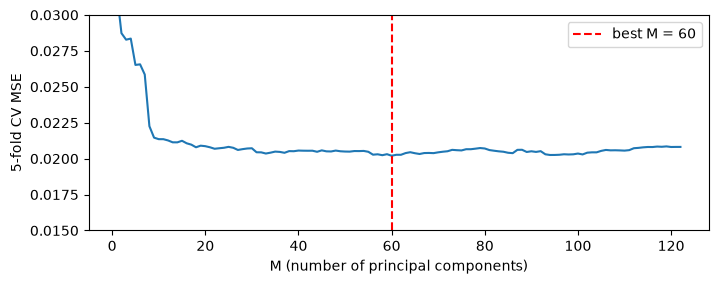

Best M = 60, CV MSE = 0.02020
PCR: test MSE = 0.01835


In [100]:
pcr = Pipeline([('scale', StandardScaler()), ('pca', PCA()), ('ols', LinearRegression())])
pcr_cv = GridSearchCV(pcr, {'pca__n_components': range(1, len(FEATS) + 1)}, cv=kf,
                      scoring='neg_mean_squared_error').fit(X_train, y_train)
best_M = pcr_cv.best_params_['pca__n_components']

plt.figure(figsize=(8, 2.8))
plt.plot(range(1, len(FEATS) + 1), -pcr_cv.cv_results_['mean_test_score'])
plt.axvline(best_M, color='red', ls='--', label=f'best M = {best_M}')
plt.xlabel('M (number of principal components)')
plt.ylabel('5-fold CV MSE')
plt.ylim(0.015, 0.03)
plt.legend()
plt.show()

print(f'Best M = {best_M}, CV MSE = {-pcr_cv.best_score_:.5f}')
report('PCR', pcr_cv.best_estimator_)

### 2(j) L1-Penalized Gradient Boosting Tree (XGBoost, α by 5-Fold CV)

In [101]:
xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                   colsample_bytree=0.8, random_state=42, n_jobs=-1)
ALPHAS = [0, 0.001, 0.01, 0.05, 0.1, 0.5, 1, 2, 5, 10]
xgb_cv = GridSearchCV(xgb, {'reg_alpha': ALPHAS}, cv=kf, scoring='neg_mean_squared_error').fit(X_train, y_train)
display(pd.DataFrame({'alpha': ALPHAS, 'CV MSE': -xgb_cv.cv_results_['mean_test_score']}).round(5).set_index('alpha').T)
print(f'Best alpha = {xgb_cv.best_params_["reg_alpha"]}, CV MSE = {-xgb_cv.best_score_:.5f}')
report('XGBoost (L1)', xgb_cv.best_estimator_)

alpha,0.000,0.001,0.010,0.050,0.100,0.500,1.000,2.000,5.000,10.000
CV MSE,0.01991,0.01989,0.01998,0.01985,0.01978,0.01973,0.01967,0.01988,0.02026,0.02182


Best alpha = 1, CV MSE = 0.01967
XGBoost (L1): test MSE = 0.01552


* XGBoost has the lowest test MSE (0.01552), beating ridge (0.01746), LASSO (0.01765), least squares (0.01797) and PCR (0.01835), since boosted trees capture non-linear effects the linear models miss.